In [ ]:
!pip list | grep torch

torch                                 2.14.1+cu130
torchao                               0.10.0
torchaudio                            2.11.0+cu130
torchcodec                            0.17.0+cu130
torchdata                             0.11.0
torchsummary                          1.5.1
torchtune                             0.6.1
torchvision                           0.29.1+cu130


In [ ]:
import torch

*   https://pytorch.org/blog/quantization-in-practice/
*   https://pytorch.org/docs/stable/quantization.html
*   https://pytorch.org/docs/stable/quantization-support.html

### Mapping function and Quantization Parameters

In [ ]:
# r - float tensor, r' - int tensor
# S [scaling factor] = (beta - alpha) / (beta_q - alpha_q)
# Z [zero point] =  -(alpha / S - alpha_q)

def quantize(float_tensor, scale, z):
  # Q(r) = round(r/S + Z)
  return torch.round(float_tensor / scale + z)

def dequantize(int_tensor, scale, z):
  # r' = (Q(r) - Z) * S
  return (int_tensor - z) * scale

In [ ]:
from torch.ao.quantization.observer import MinMaxObserver, MovingAverageMinMaxObserver, HistogramObserver

C, L = 3, 4
normal = torch.distributions.normal.Normal(0,1)
inputs = normal.sample((C, L))
print(inputs)

tensor([[ 0.6162,  0.4709, -0.7923,  1.2624],
        [-0.7220,  1.8629, -0.0321,  1.5603],
        [-0.8163,  2.7287, -1.2854,  0.8615]])


In [ ]:
observers = [MinMaxObserver(), MovingAverageMinMaxObserver(), HistogramObserver()]
for obs in observers:
  obs(inputs)
  print(obs.__class__.__name__, obs.calculate_qparams())

MinMaxObserver (tensor([0.0157]), tensor([82], dtype=torch.int32))
MovingAverageMinMaxObserver (tensor([0.0157]), tensor([82], dtype=torch.int32))
HistogramObserver (tensor([0.0157]), tensor([82], dtype=torch.int32))


In [ ]:
scale, z = observers[0].calculate_qparams()
reconstruction_error = torch.abs(dequantize(quantize(inputs, scale, z), scale, z) - inputs)
reconstruction_error

tensor([[0.0022, 0.0014, 0.0053, 0.0031],
        [0.0021, 0.0054, 0.0006, 0.0018],
        [0.0022, 0.0054, 0.0054, 0.0043]])

### Affine and Symmetric Quantization Schemes

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def get_symmetric_range(x):
  beta = torch.max(x.max(), x.min().abs())
  return -beta.item(), beta.item()

def get_affine_range(x):
  return x.min().item(), x.max().item()

def plot(plt, data, scheme):
  boundaries = get_affine_range(data) if scheme == 'affine' else get_symmetric_range(data)
  a, _, _ = plt.hist(data, density=True, bins=100)
  ymin, ymax = np.quantile(a[a>0], [0.25, 0.95])
  plt.vlines(x=boundaries, ls='--', colors='purple', ymin=ymin, ymax=ymax)

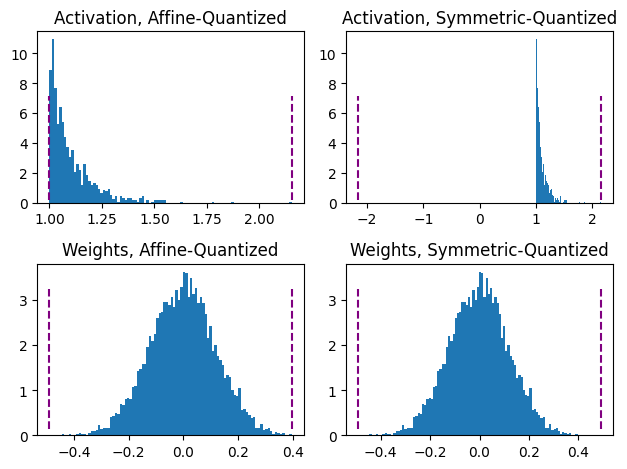

In [ ]:
act =  torch.distributions.pareto.Pareto(1, 10).sample((1, 1024)).flatten()
weights = torch.distributions.normal.Normal(0, 0.12).sample((3, 64, 7, 7)).flatten()

fig, axs = plt.subplots(2,2)
plot(axs[0, 0], act, 'affine')
axs[0, 0].set_title("Activation, Affine-Quantized")

plot(axs[0, 1], act, 'symmetric')
axs[0, 1].set_title("Activation, Symmetric-Quantized")

plot(axs[1, 0], weights, 'affine')
axs[1, 0].set_title("Weights, Affine-Quantized")

plot(axs[1, 1], weights, 'symmetric')
axs[1, 1].set_title("Weights, Symmetric-Quantized")

fig.tight_layout()
plt.show()

In [ ]:
for qscheme in [torch.per_tensor_affine, torch.per_tensor_symmetric]:
  obs = MovingAverageMinMaxObserver(qscheme=qscheme)
  obs(inputs)
  print(f"Qscheme: {qscheme} | {obs.calculate_qparams()}")

Qscheme: torch.per_tensor_affine | (tensor([0.0157]), tensor([82], dtype=torch.int32))
Qscheme: torch.per_tensor_symmetric | (tensor([0.0214]), tensor([128]))


### Per-Tensor and Per-Channel Quantization Schemes

In [ ]:
from torch.ao.quantization.observer import MovingAveragePerChannelMinMaxObserver

obs = MovingAveragePerChannelMinMaxObserver(ch_axis = 0)  # calculate qparams for all `C` channels separately
obs(inputs)
print(obs.calculate_qparams())

(tensor([0.0081, 0.0101, 0.0157]), tensor([98, 71, 82], dtype=torch.int32))


For weights quantization, symmetric-per-channel quantization provides better accuracies; per-tensor quantization performs poorly, possibly due to high variance in conv weights across channels from batchnorm folding.
[https://arxiv.org/abs/2004.09602]

https://github.com/pytorch/pytorch/blob/748d9d24940cd17938df963456c90fa1a13f3932/torch/ao/quantization/observer.py#L258

### Backend Engine

In [ ]:
backend = 'fbgemm' #'fbgemm' if x86 else 'qnnpack' intel - oneDNN
qconfig = torch.ao.quantization.get_default_qconfig(backend)
torch.backends.quantized.engine = backend

GPUs - via TensorRT and cuDNN
https://pytorch.org/docs/stable/quantization.html#note-for-native-cpu-backends

### QConfig

In [ ]:
my_qconfig = torch.ao.quantization.QConfig(
  activation=MovingAverageMinMaxObserver.with_args(qscheme=torch.per_tensor_affine),
  weight=MovingAveragePerChannelMinMaxObserver.with_args(qscheme=torch.per_channel_symmetric, dtype=torch.qint8))

my_qconfig

QConfig(activation=functools.partial(<class 'torch.ao.quantization.observer.MovingAverageMinMaxObserver'>, qscheme=torch.per_tensor_affine){}, weight=functools.partial(<class 'torch.ao.quantization.observer.MovingAveragePerChannelMinMaxObserver'>, qscheme=torch.per_channel_symmetric, dtype=torch.qint8){})

### Eager Mode v/s FX Graph Mode

*    Eager Mode Quantization is a beta feature. User needs to do fusion and specify where quantization and dequantization happens manually, also it only supports modules and not functionals.
*    FX Graph Mode Quantization is a new automated quantization framework in PyTorch, and currently it’s a prototype feature. It improves upon Eager Mode Quantization by adding support for functionals and automating the quantization process, although people might need to refactor the model to make the model compatible with FX Graph Mode Quantization (symbolically traceable with torch.fx)






FX Graph Mode automatically fuses eligible modules, inserts Quant/DeQuant stubs, calibrates the model and returns a quantized module - all in two method calls - but only for networks that are symbolic traceable. The examples below contain the calls using Eager Mode and FX Graph Mode for comparison.
https://pytorch.org/docs/stable/fx.html#torch.fx.symbolic_trace

In [ ]:
def f(a, b):
    if b == True:
        return a
    else:
        return a * 2

In [ ]:
f = torch.fx.symbolic_trace(f, concrete_args={'b': False})
assert f(3, False) == 6

https://pytorch.org/docs/stable/fx.html

### Post-Training Dynamic/Weight-only Quantization

Here the model’s weights are pre-quantized; the activations are quantized on-the-fly (“dynamic”) during inference. The simplest of all approaches, it has a one line API call in torch.quantization.quantize_dynamic. Currently only Linear and Recurrent (LSTM, GRU, RNN) layers are supported for dynamic quantization



*   Can result in higher accuracies since the clipping range is exactly calibrated for each input
*   Calibrating and quantizing the activations at each layer during runtime can add to the compute overhead



In [ ]:
from torch import nn

# toy model
m = nn.Sequential(
  nn.Conv2d(2, 64, (8,)),
  nn.ReLU(),
  nn.Linear(16, 10),
  nn.LSTM(10, 10))

m.eval()

Sequential(
  (0): Conv2d(2, 64, kernel_size=(8,), stride=(1, 1))
  (1): ReLU()
  (2): Linear(in_features=16, out_features=10, bias=True)
  (3): LSTM(10, 10)
)

In [ ]:
## EAGER MODE
from torch.ao.quantization import quantize_dynamic

model_quantized = quantize_dynamic(
    model=m, qconfig_spec={nn.LSTM, nn.Linear}, dtype=torch.qint8, inplace=False
)

/tmp/ipykernel_414/2181302342.py:4: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_quantized = quantize_dynamic(
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, 

In [ ]:
## FX MODE
from torch.ao.quantization import quantize_fx

example_inputs = (torch.randn(1, 3, 224, 224),)
qconfig_dict = {"": torch.ao.quantization.default_dynamic_qconfig}  # An empty key denotes the default applied to all modules
model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
model_quantized = quantize_fx.convert_fx(model_prepared)

/tmp/ipykernel_414/15622409.py:6: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/quantize_fx.py:146: FutureWarning: Passing a QConfig dictionary to prepare is deprecated and will not be supported in a future version. Please pass in a QConf

In [ ]:
torch.ao.quantization.default_dynamic_qconfig

QConfig(activation=functools.partial(<class 'torch.ao.quantization.observer.PlaceholderObserver'>, dtype=torch.quint8, quant_min=0, quant_max=255, is_dynamic=True){}, weight=functools.partial(<class 'torch.ao.quantization.observer.MinMaxObserver'>, dtype=torch.qint8, qscheme=torch.per_tensor_symmetric){})

### Post-Training Static Quantization (PTQ)

PTQ also pre-quantizes model weights but instead of calibrating activations on-the-fly, the clipping range is pre-calibrated and fixed (“static”) using validation data. Activations stay in quantized precision between operations during inference. About 100 mini-batches of representative data are sufficient to calibrate the observers

*   Static quantization has faster inference than dynamic quantization because it eliminates the float<->int conversion costs between layers
*   Static quantized models may need regular re-calibration to stay robust against distribution-drift



In [ ]:
# Static quantization of a model consists of the following steps:

#     Fuse modules
#     Insert Quant/DeQuant Stubs
#     Prepare the fused module (insert observers before and after layers)
#     Calibrate the prepared module (pass it representative data)
#     Convert the calibrated module (replace with quantized version)

import torch
from torch import nn
import copy

backend = "fbgemm"  # running on a x86 CPU. Use "qnnpack" if running on ARM.

model = nn.Sequential(
     nn.Conv2d(2, 64, 3),
     nn.ReLU(),
     nn.Conv2d(64, 128, 3),
     nn.ReLU()
)

In [ ]:
## EAGER MODE
m = copy.deepcopy(model)
m.eval()

"""Fuse
- Inplace fusion replaces the first module in the sequence with the fused module, and the rest with identity modules
"""
torch.ao.quantization.fuse_modules(m, ['0','1'], inplace=True) # fuse first Conv-ReLU pair
torch.ao.quantization.fuse_modules(m, ['2','3'], inplace=True) # fuse second Conv-ReLU pair

"""Insert stubs"""
m = nn.Sequential(torch.ao.quantization.QuantStub(),
                  *m,
                  torch.ao.quantization.DeQuantStub())

"""Prepare"""
m.qconfig = torch.ao.quantization.get_default_qconfig(backend)
torch.ao.quantization.prepare(m, inplace=True)

"""Calibrate
- This example uses random data for convenience. Use representative (validation) data instead.
"""
with torch.inference_mode():
  for _ in range(10):
    x = torch.rand(1, 2, 28, 28)
    m(x)

"""Convert"""
torch.ao.quantization.convert(m, inplace=True)

"""Check"""
print(m[1].weight().element_size()) # 1 byte instead of 4 bytes for FP32

/tmp/ipykernel_414/213743822.py:18: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.prepare(m, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTor

1


/tmp/ipykernel_414/213743822.py:29: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.convert(m, inplace=True)


In [ ]:
m[1].weight()

tensor([[[[ 0.0178,  0.1606,  0.1053],
          [-0.0981,  0.1499, -0.1927],
          [ 0.1303, -0.0303,  0.0839]],

         [[ 0.1356, -0.1320,  0.0054],
          [-0.1142, -0.1249,  0.2266],
          [ 0.0785, -0.1999, -0.1356]]],


        [[[-0.2340,  0.2011, -0.2139],
          [-0.0695,  0.1554,  0.1737],
          [-0.2157,  0.1371, -0.1609]],

         [[ 0.0091,  0.0731, -0.0676],
          [ 0.2322, -0.2102,  0.1828],
          [ 0.1408, -0.1079, -0.0932]]],


        [[[ 0.0200, -0.1553,  0.0234],
          [ 0.1119, -0.1469,  0.0985],
          [ 0.0534,  0.0818,  0.0635]],

         [[-0.0284, -0.1653,  0.1920],
          [-0.2087, -0.1720,  0.1135],
          [-0.1186,  0.2121, -0.0618]]],


        ...,


        [[[ 0.0381, -0.1538, -0.0996],
          [ 0.0469,  0.1743,  0.1685],
          [ 0.0117,  0.0044,  0.1231]],

         [[ 0.0527,  0.0015, -0.0850],
          [-0.0249, -0.1612, -0.1875],
          [ 0.1319, -0.1201, -0.1319]]],


        [[[-0.1091,  0.15

In [ ]:
## FX GRAPH
from torch.ao.quantization import quantize_fx

m = copy.deepcopy(model)
m.eval()
qconfig_dict = {"": torch.ao.quantization.get_default_qconfig(backend)}

# Prepare
example_inputs = (torch.randn(1, 3, 224, 224),)
model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)

# Calibrate - Use representative (validation) data.
with torch.inference_mode():
  for _ in range(10):
    x = torch.rand(1, 2, 28, 28)
    model_prepared(x)

# quantize
model_quantized = quantize_fx.convert_fx(model_prepared)

/tmp/ipykernel_414/750729956.py:10: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
/tmp/ipykernel_414/750729956.py:19: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.q

### SENSITIVITY ANALYSIS

In [ ]:
# ONE-AT-A-TIME SENSITIVITY ANALYSIS

for quantized_layer, _ in model.named_modules():
  print("Only quantizing layer: ", quantized_layer)

  # The module_name key allows module-specific qconfigs.
  qconfig_dict = {"": None,
  "module_name":[(quantized_layer, torch.quantization.get_default_qconfig(backend))]}

  example_inputs = (torch.randn(1, 3, 224, 224),)
  model_prepared = quantize_fx.prepare_fx(model, qconfig_dict, example_inputs)
  # calibrate
  model_quantized = quantize_fx.convert_fx(model_prepared)
  # evaluate(model)

/tmp/ipykernel_414/1147990886.py:11: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(model, qconfig_dict, example_inputs)
/tmp/ipykernel_414/1147990886.py:13: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torc

Only quantizing layer:  
Only quantizing layer:  0
Only quantizing layer:  1
Only quantizing layer:  2
Only quantizing layer:  3


 Numeric Suite - https://pytorch.org/tutorials/prototype/numeric_suite_tutorial.html

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets
import torchvision.transforms as transforms
import os
import torch.ao.quantization
import torch.ao.ns._numeric_suite as ns
from torch.ao.quantization import (
    default_eval_fn,
    default_qconfig,
    quantize,
)

In [ ]:
float_model = torchvision.models.quantization.resnet18(pretrained=True, quantize=False)
float_model.to('cpu')
float_model.eval()
float_model.fuse_model()
float_model.qconfig = torch.quantization.default_qconfig
img_data = (torch.rand(2, 3, 10, 10, dtype=torch.float), torch.randint(0, 1, (2,), dtype=torch.long))
qmodel = quantize(float_model, default_eval_fn, [[img_data]], inplace=False)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 89.8MB/s]
/tmp/ipykernel_414/409614095.py:7: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  qmodel = quantize(float_model, default_eval_fn, [[img_data]], inplace=False)


In [ ]:
def compute_error(x, y):
    Ps = torch.norm(x)
    Pn = torch.norm(x - y)
    return 20 * torch.log10(Ps/Pn)

wt_compare_dict = ns.compare_weights(float_model.state_dict(), qmodel.state_dict())
for key in wt_compare_dict:
    print(key, compute_error(wt_compare_dict[key]['float'], wt_compare_dict[key]['quantized'].dequantize()))

print("---")

act_compare_dict = ns.compare_model_outputs(float_model, qmodel, img_data[0])
for key in act_compare_dict:
    print(key, compute_error(act_compare_dict[key]['float'][0], act_compare_dict[key]['quantized'][0].dequantize()))


conv1.weight tensor(31.6638)
layer1.0.conv1.weight tensor(30.6450)
layer1.0.conv2.weight tensor(31.1528)
layer1.1.conv1.weight tensor(32.1438)
layer1.1.conv2.weight tensor(31.2477)
layer2.0.conv1.weight tensor(30.9890)
layer2.0.conv2.weight tensor(28.8233)
layer2.0.downsample.0.weight tensor(31.5558)
layer2.1.conv1.weight tensor(30.7668)
layer2.1.conv2.weight tensor(28.4516)
layer3.0.conv1.weight tensor(30.9247)
layer3.0.conv2.weight tensor(26.6841)
layer3.0.downsample.0.weight tensor(28.7825)
layer3.1.conv1.weight tensor(28.9707)
layer3.1.conv2.weight tensor(25.6784)
layer4.0.conv1.weight tensor(26.8495)
layer4.0.conv2.weight tensor(25.8394)
layer4.0.downsample.0.weight tensor(28.6355)
layer4.1.conv1.weight tensor(26.8758)
layer4.1.conv2.weight tensor(28.4319)
fc._packed_params._packed_params tensor(32.6505)
---
conv1.stats tensor(37.3449, grad_fn=<MulBackward0>)
layer1.0.conv1.stats tensor(30.0059, grad_fn=<MulBackward0>)
layer1.0.conv2.stats tensor(28.6244, grad_fn=<MulBackward0>)
l

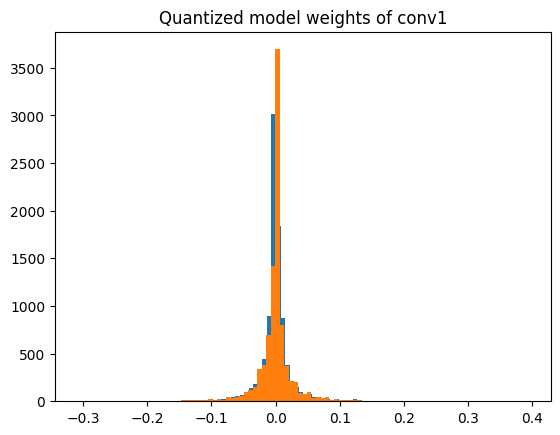

In [ ]:
import matplotlib.pyplot as plt

f = wt_compare_dict['conv1.weight']['float'].flatten()
plt.hist(f, bins = 100)

q = wt_compare_dict['conv1.weight']['quantized'].flatten().dequantize()
plt.hist(q, bins = 100)
plt.title("Quantized model weights of conv1")
plt.show()

### RECOMMENDATIONS FOR YOUR WORKFLOW

![](https://drive.google.com/uc?export=view&id=1ij7GElwiKFNmJ221aKpkDRwMj5i-2DLh)



*   Large (10M+ parameters) models are more robust to quantization error
*   Quantizing a model from a FP32 checkpoint provides better accuracy than training an INT8 model from scratch
*   Dynamic Quantization is an easy first step, especially if your model has many Linear or Recurrent layers
*   Use symmetric-per-channel quantization with MinMax observers for quantizing weights. Use affine-per-tensor quantization with MovingAverageMinMax observers for quantizing activations
*   Use metrics like SQNR to identify which layers are most suscpetible to quantization error. Turn off quantization on these layers

Eager mode https://pytorch.org/docs/stable/quantization.html#eager-mode-quantization



*   https://pytorch.org/docs/stable/quantization.html#post-training-dynamic-quantization
*   https://pytorch.org/docs/stable/quantization.html#post-training-static-quantization


FX Graph https://pytorch.org/docs/stable/quantization.html#prototype-fx-graph-mode-quantization



*   https://pytorch.org/tutorials/prototype/fx_graph_mode_ptq_static.html
*   https://pytorch.org/tutorials/prototype/fx_graph_mode_ptq_dynamic.html





## New forkflow with torchao



In [ ]:
!pip install torchao

In [ ]:
import copy
import torch

class ToyLinearModel(torch.nn.Module):
    def __init__(self, m: int, n: int, k: int):
        super().__init__()
        self.linear1 = torch.nn.Linear(m, n, bias=False)
        self.linear2 = torch.nn.Linear(n, k, bias=False)

    def forward(self, x):
        x = self.linear1(x)
        x = self.linear2(x)
        return x

model = ToyLinearModel(1024, 1024, 1024).eval()

# Optional: compile model for faster inference and generation
model = torch.compile(model, mode="max-autotune", fullgraph=True)
model_f32 = copy.deepcopy(model)


In [ ]:
from torchao.quantization import Int4DynamicActivationInt4WeightConfig, quantize_
quantize_(model, Int4DynamicActivationInt4WeightConfig())

In [ ]:
from torchao.utils import (
    benchmark_model,
    unwrap_tensor_subclass,
)

num_runs = 100
torch._dynamo.reset()
example_inputs = (torch.randn(1, 1024, dtype=torch.float32),)
f32_time = benchmark_model(model_f32, num_runs, example_inputs)
int4_time = benchmark_model(model, num_runs, example_inputs)

print("f32 mean time: %0.3f ms" % f32_time)
print("int4 mean time: %0.3f ms" % int4_time)
print("speedup: %0.1fx" % (f32_time / int4_time))

/usr/local/lib/python3.13/dist-packages/torch/_functorch/_aot_autograd/autograd_cache.py:707: UserWarning: LinearActivationQuantizedTensor does not implement _stable_hash_for_caching. For PT2-compatible tensor subclasses, it is recommended to implement _stable_hash_for_caching(self) -> str for stable AOT autograd caching.
  warn_once(


f32 mean time: 0.215 ms
int4 mean time: 0.107 ms
speedup: 2.0x


In [ ]:
import os
torch.save(model, "/tmp/int4_model.pt")
torch.save(model_f32, "/tmp/f32_model.pt")
int4_model_size_mb = os.path.getsize("/tmp/int4_model.pt") / 1024 / 1024
f32_model_size_mb = os.path.getsize("/tmp/f32_model.pt") / 1024 / 1024

print("int4 model size: %.2f MB" % int4_model_size_mb)

print("f32 model size: %.2f MB" % f32_model_size_mb)


int4 model size: 1.01 MB
f32 model size: 8.00 MB


### Neural Network Compression Framework (NNCF)

In [ ]:
!git clone https://github.com/openvinotoolkit/nncf

Cloning into 'nncf'...
remote: Enumerating objects: 103820, done.
remote: Counting objects: 100% (930/930), done.
remote: Compressing objects: 100% (533/533), done.
remote: Total 103820 (delta 687), reused 397 (delta 397), pack-reused 102890 (from 3)
Receiving objects: 100% (103820/103820), 73.13 MiB | 21.46 MiB/s, done.
Resolving deltas: 100% (70071/70071), done.


In [ ]:
# %%capture
%cd nncf
!pip install .[torch]
%cd /content

/content/nncf
Processing ./.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 15.2 MB/s  0:00:00
  Created wheel for nncf: filename=nncf-3.6.0.dev0+571822163-py3-none-any.whl size=803941 sha256=096fc601cf8adf5af00d7a6bc6a86424295c9b9cd438d1cb8e42055beced6791
  Stored in directory: /tmp/pip-ephem-wheel-cache-70b37d_k/wheels/6d/e0/88/fc57195154b6b185a52dc73cff95dc1de3abc6b98b88029e3e
Successfully built nncf
  Attempting uninstall: networkx
    Found existing installation: networkx 3.7
    Uninstalling networkx-3.7:
      Successfully uninstalled networkx-3.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [nncf]
/content


In [ ]:
import torch
import nncf.torch  # Important - must be imported before any other external package that depends on torch

https://github.com/openvinotoolkit/nncf/tree/develop
https://github.com/openvinotoolkit/nncf/blob/develop/docs/compression_algorithms/Quantization.md
https://github.com/openvinotoolkit/nncf/blob/develop/examples/torch/classification/configs/quantization/inception_v3_imagenet_int8.json

https://dev-discuss.pytorch.org/t/torch-ao-quantization-migration-plan/2810
https://docs.pytorch.org/ao/stable

---

# ONNX and TensorRT

## 1. Overview

**ONNX (Open Neural Network Exchange)** is an interoperable format for representing neural network graphs, weights and input/output information. A PyTorch model can be exported to an `.onnx` file and deployed in different inference frameworks.

**ONNX Runtime** executes ONNX models using CPU, CUDA and other execution providers. It also provides post-training quantization tools.

**NVIDIA TensorRT** is a compiler and runtime for inference on NVIDIA GPUs. It parses compatible ONNX graphs, optimizes layers and selects efficient kernels, and produces serialized inference engines (`.engine`). TensorRT engines depend on the hardware and software environment used to build them.

A typical deployment path is:

```text
PyTorch model → ONNX FP32 → ONNX Runtime (CPU/GPU)
                           ├── ONNX Runtime dynamic INT8
                           ├── ONNX Runtime static INT8 (Q/DQ)
                           └── TensorRT FP16 or calibrated INT8
```

**FP16** is a floating-point precision mode. **INT8 quantization** maps values to integers using scaling parameters. Static INT8 quantization requires representative calibration data.

## 2. Exporting a PyTorch model to ONNX

First, train a compact fully connected network on the `sklearn` handwritten-digits dataset. The model will be used throughout the ONNX and TensorRT sections.

In [ ]:
%pip -q install onnx onnxruntime onnxscript scikit-learn

In [ ]:
import numpy as np
import torch
from torch import nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(42)

images, labels = load_digits(return_X_y=True)
images = (images / 16.0).astype(np.float32)
train_x, test_x, train_y, test_y = train_test_split(
    images, labels, test_size=0.2, random_state=42, stratify=labels
)

export_model = nn.Sequential(
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
)
optimizer = torch.optim.Adam(export_model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

x_train_tensor = torch.from_numpy(train_x)
y_train_tensor = torch.from_numpy(train_y).long()
for epoch in range(30):
    optimizer.zero_grad()
    loss = loss_fn(export_model(x_train_tensor), y_train_tensor)
    loss.backward()
    optimizer.step()

export_model.eval()
with torch.no_grad():
    predictions = export_model(torch.from_numpy(test_x)).argmax(dim=1).numpy()
print(f"PyTorch accuracy: {(predictions == test_y).mean():.2%}")

PyTorch accuracy: 94.44%


In [ ]:
from pathlib import Path
import onnx
import onnxruntime as ort

onnx_fp32_path = "digits_fp32.onnx"
dummy_input = torch.from_numpy(test_x[:1].copy())

torch.onnx.export(
    export_model,
    (dummy_input,),
    onnx_fp32_path,
    input_names=["input"],
    output_names=["logits"],
    opset_version=18,
    dynamo=True,
)

onnx.checker.check_model(onnx.load(onnx_fp32_path))
fp32_session = ort.InferenceSession(onnx_fp32_path, providers=["CPUExecutionProvider"])
with torch.no_grad():
    pytorch_logits = export_model(dummy_input).numpy()
onnx_logits = fp32_session.run(None, {"input": dummy_input.numpy()})[0]

print("ONNX export validated")
print("Maximum output difference:", np.max(np.abs(pytorch_logits - onnx_logits)))
print("ONNX file size:", Path(onnx_fp32_path).stat().st_size, "bytes")

[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX export validated
Maximum output difference: 1.1920929e-06
ONNX file size: 4614 bytes


## 3. Quantization with ONNX Runtime

**Dynamic quantization** stores quantized weights and computes activation quantization parameters during inference. It is commonly used for networks with linear layers.

**Static quantization** uses a calibration dataset to determine activation ranges before inference. In a **Q/DQ ONNX graph**, `QuantizeLinear` and `DequantizeLinear` nodes explicitly express the quantization scales and locations; compatible graphs can also be imported into TensorRT.

In [ ]:
from onnxruntime.quantization import quantize_dynamic, QuantType

onnx_dynamic_int8_path = "digits_dynamic_int8.onnx"
quantize_dynamic(
    model_input=onnx_fp32_path,
    model_output=onnx_dynamic_int8_path,
    weight_type=QuantType.QInt8,
)

dynamic_session = ort.InferenceSession(
    onnx_dynamic_int8_path, providers=["CPUExecutionProvider"]
)
dynamic_logits = dynamic_session.run(None, {"input": dummy_input.numpy()})[0]
print("Max difference after dynamic INT8:", np.max(np.abs(onnx_logits - dynamic_logits)))

for p in [onnx_fp32_path, onnx_dynamic_int8_path]:
    print(f"{p}: {Path(p).stat().st_size / 1024:.1f} KiB")

Max difference after dynamic INT8: 0.39864016
digits_fp32.onnx: 4.5 KiB
digits_dynamic_int8.onnx: 9.0 KiB


### Static INT8 quantization

For calibration, use representative **training** inputs (not test-set inputs). The quantizer estimates the activation ranges and inserts Q/DQ operations into the exported graph. Quantized ONNX operator support varies by execution provider and TensorRT version.

In [ ]:
from onnxruntime.quantization import (
    CalibrationDataReader, QuantFormat, QuantType, quantize_static
)

class DigitsCalibrationReader(CalibrationDataReader):
    def __init__(self, samples, count=128):
        self.iterator = iter(
            {"input": row[None, :].astype(np.float32)}
            for row in samples[:count]
        )

    def get_next(self):
        return next(self.iterator, None)

onnx_qdq_path = "digits_static_qdq_int8.onnx"
quantize_static(
    model_input=onnx_fp32_path,
    model_output=onnx_qdq_path,
    calibration_data_reader=DigitsCalibrationReader(train_x),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    op_types_to_quantize=["MatMul", "Gemm"],
    extra_options={"ActivationSymmetric": True, "WeightSymmetric": True},
)

onnx.checker.check_model(onnx.load(onnx_qdq_path))
static_session = ort.InferenceSession(onnx_qdq_path, providers=["CPUExecutionProvider"])
static_logits = static_session.run(None, {"input": dummy_input.numpy()})[0]
print("Max difference after static INT8:", np.max(np.abs(onnx_logits - static_logits)))
print(f"Static INT8 ONNX size: {Path(onnx_qdq_path).stat().st_size / 1024:.1f} KiB")

Max difference after static INT8: 2.7310138
Static INT8 ONNX size: 12.1 KiB


In [ ]:
def onnx_accuracy(session, features, targets):
    correct = 0
    for sample, target in zip(features, targets):
        logits = session.run(None, {"input": sample[None, :].astype(np.float32)})[0]
        correct += int(np.argmax(logits[0]) == target)
    return correct / len(targets)

for name, runtime in [
    ("FP32", fp32_session),
    ("Dynamic INT8", dynamic_session),
    ("Static INT8 Q/DQ", static_session),
]:
    print(f"{name:16s} accuracy: {onnx_accuracy(runtime, test_x, test_y):.2%}")

FP32             accuracy: 94.44%
Dynamic INT8     accuracy: 94.17%
Static INT8 Q/DQ accuracy: 89.72%


## 4. TensorRT export and inference

TensorRT is intended for NVIDIA GPUs and requires compatible CUDA drivers and TensorRT tools. The `trtexec` utility is distributed with full TensorRT installations or NVIDIA TensorRT containers; it is not normally present in standard Google Colab runtimes.

On a machine with `trtexec` installed, convert the ONNX model into a TensorRT engine:

```bash
# Enable FP16 tactics
trtexec --onnx=digits_fp32.onnx --saveEngine=digits_fp16.engine --fp16

# Use the explicitly quantized ONNX graph for INT8
trtexec --onnx=digits_static_qdq_int8.onnx --saveEngine=digits_int8.engine

# Run a benchmark with an existing engine
trtexec --loadEngine=digits_fp16.engine
```

`--fp16` permits TensorRT to use FP16 kernels where advantageous; it does not force every operation into FP16. For INT8, a compatible Q/DQ graph specifies the quantization scales. An arbitrary FP32 model does **not** become properly calibrated simply by adding `--int8`.

TensorRT may reject unsupported operators or quantization patterns, so always inspect parser/build logs.

In [ ]:
import shutil
import subprocess

trtexec = shutil.which("trtexec")
if not torch.cuda.is_available():
    print("TensorRT build skipped: an NVIDIA CUDA GPU is required.")
elif trtexec is None:
    print("TensorRT build skipped: trtexec is not installed.")
else:
    subprocess.run([
        trtexec,
        f"--onnx={onnx_fp32_path}",
        "--saveEngine=digits_fp16.engine",
        "--fp16",
    ], check=True)

TensorRT build skipped: trtexec is not installed.


**References:** [PyTorch ONNX exporter](https://docs.pytorch.org/docs/stable/onnx) · [ONNX Runtime quantization](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html) · [TensorRT ONNX deployment](https://docs.nvidia.com/deeplearning/tensorrt/latest/getting-started/quick-start-onnx-deployment.html) · [TensorRT quantization](https://docs.nvidia.com/deeplearning/tensorrt/latest/inference-library/work-with-quantized-types.html).

**Домашнее задание**: реализовать Post Training Quantization для предобученной float32 torch модели на выбранном наборе данных. Квантизация обязательно должна проводиться с использованием калибровочной подвыборки. К результатам прилагаются мини результаты исследования влияния гиперпараметров квантизации (см. начало ноутбка). Необходимо показать разные варианты с учетом и без SENSITIVITY анализа. Разрешается использовать дополнительные фреймворки после обсуждения. Добавить сравнение с экспортированной ONNX и TensorRT весами. Важно наличие таблиц скорость / качество / размер.

# Реализация домашнего задания

Для решения задачи буду использовать модель VGG из прошлого дз

In [ ]:
import torch
from torch import nn
from collections import OrderedDict, defaultdict

In [ ]:
# определяем класс модели

class VGG(nn.Module):
  ARCH = [64, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M']

  def __init__(self) -> None:
    super().__init__()

    layers = []
    counts = defaultdict(int)

    def add(name: str, layer: nn.Module) -> None:
      layers.append((f"{name}{counts[name]}", layer))
      counts[name] += 1

    in_channels = 3
    for x in self.ARCH:
      if x != 'M':
        # conv-bn-relu
        add("conv", nn.Conv2d(in_channels, x, 3, padding=1, bias=False))
        add("bn", nn.BatchNorm2d(x))
        add("relu", nn.ReLU(True))
        in_channels = x
      else:
        # maxpool
        add("pool", nn.MaxPool2d(2))

    self.backbone = nn.Sequential(OrderedDict(layers))
    self.classifier = nn.Linear(512, 10)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    # backbone: [N, 3, 32, 32] => [N, 512, 2, 2]
    x = self.backbone(x)

    # avgpool: [N, 512, 2, 2] => [N, 512]
    x = x.mean([2, 3])

    # classifier: [N, 512] => [N, 10]
    x = self.classifier(x)
    return x

In [ ]:
# проверка выхода
model = VGG()
tensor = torch.randn(2, 3, 32, 32)
print(model(tensor).shape)

torch.Size([2, 10])


In [ ]:
def download_url(url, model_dir='.', overwrite=False):
    import os, sys, ssl
    from urllib.request import urlretrieve
    ssl._create_default_https_context = ssl._create_unverified_context
    target_dir = url.split('/')[-1]
    model_dir = os.path.expanduser(model_dir)
    try:
        if not os.path.exists(model_dir):
            os.makedirs(model_dir)
        model_dir = os.path.join(model_dir, target_dir)
        cached_file = model_dir
        if not os.path.exists(cached_file) or overwrite:
            sys.stderr.write('Downloading: "{}" to {}\n'.format(url, cached_file))
            urlretrieve(url, cached_file)
        return cached_file
    except Exception as e:
        # remove lock file so download can be executed next time.
        os.remove(os.path.join(model_dir, 'download.lock'))
        sys.stderr.write('Failed to download from url %s' % url + '\n' + str(e) + '\n')
        return None



In [ ]:
# загрузка чекпоинта

checkpoint_url = "https://hanlab18.mit.edu/files/course/labs/vgg.cifar.pretrained.pth"

checkpoint = torch.load(
    download_url(checkpoint_url),
    map_location="cpu",
)

model.load_state_dict(checkpoint["state_dict"])
model.eval()

Downloading: "https://hanlab18.mit.edu/files/course/labs/vgg.cifar.pretrained.pth" to ./vgg.cifar.pretrained.pth


VGG(
  (backbone): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (r

In [ ]:
# загрузка датасета
from torchvision.datasets import CIFAR10
from torchvision.transforms import ToTensor

CIFAR10.url = (
    "https://huggingface.co/datasets/"
    "MIT-OL-AI-D/cifar-10-python/"
    "resolve/main/cifar-10-python.tar.gz"
)

In [ ]:
test_dataset = CIFAR10(
    root="data/cifar10",
    train=False,
    download=True,
    transform=ToTensor(),
)

image, label = test_dataset[0]

print(len(test_dataset))
print(image.shape)
print(image.dtype)
print(label)

100%|██████████| 170M/170M [00:04<00:00, 41.5MB/s]


10000
torch.Size([3, 32, 32])
torch.float32
3


In [ ]:
# загрузка dataloader и проверка корректности работы
from torch.utils.data import DataLoader

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
)

images, labels = next(iter(test_loader))
print(images.shape)
print(labels.shape)

with torch.inference_mode():
  logits = model(images)
  print(logits.shape)

torch.Size([64, 3, 32, 32])
torch.Size([64])
torch.Size([64, 10])


In [ ]:
# тренировочное accuracy на первых 64 картинках

with torch.inference_mode():
  logits = model(images)
  logits = logits.argmax(dim=1)
  num_correct = (logits == labels).sum()
  print(f"accuracy: {round(num_correct.item() / labels.size(0), 2)}")

accuracy: 0.89


In [ ]:
# accuracy модели в torch.float32

total_correct = 0
total_images = 0
with torch.inference_mode():
  for images, labels in test_loader:
    logits = model(images)
    logits = logits.argmax(dim=1)
    num_correct = (logits == labels).sum().item()
    total_correct += num_correct
    total_images += labels.size(0)

accuracy = total_correct / total_images * 100
print(f"FP32 accuracy: {accuracy:.2f}%")

FP32 accuracy: 92.95%


baseline модель показала accuracy: 92.95%

## Вычисление accuracy модели после квантизации INT8


In [ ]:
# загружаем калибровочную выборку
train_dataset = CIFAR10(
    root="data/cifar10",
    train=True,
    download=True,
    transform=ToTensor(),
)

print(len(train_dataset))

image, label = train_dataset[0]
print(image.shape)

50000
torch.Size([3, 32, 32])


In [ ]:
# создание калибровочного датасета
from torch.utils.data import Subset

gen = torch.Generator().manual_seed(42)

indices = torch.randperm(len(train_dataset), generator=gen)[:512]

calibration_dataset = Subset(train_dataset, indices)

print(len(calibration_dataset))

image, label = calibration_dataset[0]
print(image.shape)
print(label)

512
torch.Size([3, 32, 32])
6


In [ ]:
# создание калибровочного лоадера

calibration_loader = DataLoader(
    dataset=calibration_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

print(len(calibration_loader))

images, labels = next(iter(calibration_loader))

print(images.shape)
print(labels.shape)


16
torch.Size([32, 3, 32, 32])
torch.Size([32])


## Эксперимент с дефолтными конфигурациями

In [ ]:
# prepare
model_qt = copy.deepcopy(model)
model_qt.eval()

qconfig_dict = {
    "": torch.ao.quantization.get_default_qconfig("fbgemm")
}

example_inputs = (torch.randn(1, 3, 32, 32),)

model_prepared = quantize_fx.prepare_fx(model_qt, qconfig_dict, example_inputs)

/tmp/ipykernel_414/3152832466.py:11: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(model_qt, qconfig_dict, example_inputs)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/quantize_fx.py:146: FutureWarning: Passing a QConfig dictionary to prepare is deprecated and will not be supported in a future version. Please pass 

In [ ]:
# calibration
model_prepared.eval()

with torch.inference_mode():
  for images, _ in calibration_loader:
    model_prepared(images)

print(model_prepared.activation_post_process_0)

HistogramObserver(min_val=0.0, max_val=1.0)


In [ ]:
model_convert = quantize_fx.convert_fx(model_prepared)
model_convert.eval()

/tmp/ipykernel_414/367301245.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_convert = quantize_fx.convert_fx(model_prepared)


GraphModule(
  (backbone): Module(
    (conv0): QuantizedConvReLU2d(3, 64, kernel_size=(3, 3), stride=(1, 1), scale=0.01923838071525097, zero_point=0, padding=(1, 1))
    (conv1): QuantizedConvReLU2d(64, 128, kernel_size=(3, 3), stride=(1, 1), scale=0.016379820182919502, zero_point=0, padding=(1, 1))
    (pool0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): QuantizedConvReLU2d(128, 256, kernel_size=(3, 3), stride=(1, 1), scale=0.007542027626186609, zero_point=0, padding=(1, 1))
    (conv3): QuantizedConvReLU2d(256, 256, kernel_size=(3, 3), stride=(1, 1), scale=0.008851083926856518, zero_point=0, padding=(1, 1))
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv4): QuantizedConvReLU2d(256, 512, kernel_size=(3, 3), stride=(1, 1), scale=0.006603505462408066, zero_point=0, padding=(1, 1))
    (conv5): QuantizedConvReLU2d(512, 512, kernel_size=(3, 3), stride=(1, 1), scale=0.007497427985072136, zero_poi

In [ ]:
# convertation и вычисление accuracy
model_convert = quantize_fx.convert_fx(model_prepared)
model_convert.eval()

total_correct = 0
total_images = 0
with torch.inference_mode():
  for images, labels in test_loader:
    logits = model_convert(images)
    logits = logits.argmax(dim=1)
    num_correct = (logits == labels).sum().item()
    total_correct += num_correct
    total_images += labels.size(0)

accuracy = (total_correct / total_images) * 100

print(f"INT8 accuracy: {accuracy:.2f}%")

/tmp/ipykernel_414/2384646441.py:2: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_convert = quantize_fx.convert_fx(model_prepared)


RuntimeError: Input type (c10::quint8) and bias type (float) should be the same

квантованная модель INT8 accuracy: 92.92%. Причем модель показал почти такие же значения метрики, как изначальный бейслайн

In [ ]:
# Проверка, что свертки действительно стали квантованными
print(model_convert)

In [ ]:
# дельта accuracy FP32 И INT8
delta_fp32_int8 = abs(92.95 - 92.92)

print(f"дельта: {delta_fp32_int8:.2f}")

In [ ]:
# измерение памяти
torch.save(model.state_dict(), "vgg_fp32.pth")
torch.save(model_convert.state_dict(), "vgg_int8.pth")

model_f32_size = os.path.getsize("vgg_fp32.pth") / 1024 ** 2
model_int8_size = os.path.getsize("vgg_int8.pth") / 1024 ** 2

fp32_int8_size = model_f32_size / model_int8_size

print(f"FP32 size MiB: {model_f32_size:.2f}")
print(f"INT8 size MiB: {model_int8_size:.2f}")
print(f"Compression  ratio: {fp32_int8_size:.2f}х")

Память сжалась почти в 4 раза

In [ ]:
# измерение latency
import time

def measure_latency(model, x, warmup=20, num_runs=100):
  with torch.no_grad():
    model.eval()
    for _ in range(warmup):
      model(x)
    all_time = 0
    for _ in range(num_runs):
      start = time.perf_counter()
      model(x)
      end = time.perf_counter()
      all_time += end - start

    return all_time * 1000 / num_runs # в милисекундах

x = torch.rand(1, 3, 32, 32)

latency_fp32 = measure_latency(model, x)
latency_int8 = measure_latency(model_convert, x)

ratio = latency_fp32 / latency_int8

print(f"FP32 latency: {latency_fp32:.2f}")
print(f"INT8 latency: {latency_int8:.2f}")
print(f"ratio: {ratio:.2f}х")

Общий вывод: сжав размерность почти в 4 раза и ускорив время инференса вдвое точность модели испортилась всего лишь на 0.03 пункта

## Эксперименты с гиперпараметрами квантизации

| Гиперпараметр | Варианты |
|---|---|
| Observer | MinMax, Histogram, MovingAverageMinMax |
| Квантизация весов | Per-tensor, Per-channel |
| Размер калибровочной выборки | 32, 128, 512, 2048 |
| Выбор слоёв | Полная квантизация, Sensitivity Analysis |

In [ ]:
# вынесение вычисления accuracy в функцию
def evaluate_accuracy(model, dataloader):
  with torch.inference_mode():
    total_correct = 0
    total_images = 0
    model.eval()
    for images, labels in dataloader:
      logits = model(images)
      logits = logits.argmax(dim=1)
      num_correct = (logits == labels).sum().item()
      total_correct += num_correct
      total_images += labels.size(0)

    accuracy = 100 * (total_correct / total_images)
    return accuracy

In [ ]:
# создание выборок
gen.manual_seed(42)

indices = torch.randperm(len(train_dataset), generator=gen)

calibration_dataset = Subset(train_dataset, indices[:512])
validation_dataset = Subset(train_dataset, indices[2048:7048])

calibration_loader = DataLoader(
    dataset=calibration_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

validation_loader = DataLoader(
    dataset=validation_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
)

print(len(calibration_dataset))
print(len(validation_dataset))

In [ ]:
# контрольные значения на валидационной выборке
fp32_acc = evaluate_accuracy(model, validation_loader)
int8_acc = evaluate_accuracy(model_convert, validation_loader)

print(f"FP32 accuracy: {fp32_acc:.2f}")
print(f"INT8 accuracy: {int8_acc:.2f}")

In [ ]:
# проверяем мин макс
from torch.ao.quantization.observer import MinMaxObserver
from torch.ao.quantization.observer import PerChannelMinMaxObserver

qconfig_minmax = torch.ao.quantization.QConfig(
    activation=MinMaxObserver.with_args(dtype=torch.quint8, qscheme=torch.per_tensor_affine),
    weight=PerChannelMinMaxObserver.with_args(dtype=torch.qint8, qscheme=torch.per_channel_symmetric),
)

print(qconfig_minmax)

print(qconfig_minmax.activation().qscheme)
print(qconfig_minmax.weight().qscheme)

In [ ]:
model_minmax = copy.deepcopy(model)
model_minmax.eval()

qconfig_dict_minmax = {
    "": qconfig_minmax
}

model_pre_minmax = quantize_fx.prepare_fx(model_minmax, qconfig_dict_minmax, example_inputs)
model_pre_minmax.eval()

with torch.inference_mode():
  for images, _ in calibration_loader:
    model_pre_minmax(images)

print(model_pre_minmax.activation_post_process_0)

In [ ]:
model_convert_minmax = quantize_fx.convert_fx(model_pre_minmax)

int8_minmax_acc = evaluate_accuracy(model_convert_minmax, validation_loader)

print(f"INT8 minmax accuracy: {int8_minmax_acc:.2f}")

97.64 % minmax, но пока помним, что это на валидационной, а прошлые модели проверялись на тесте

In [ ]:
# вычисление accuracy на валидационной выборке, остальными двумя моделям

fp32_def_acc = evaluate_accuracy(model, validation_loader)
int8_hist_acc = evaluate_accuracy(model_convert, validation_loader)

print(f"FP32  accuracy: {fp32_def_acc:.2f}")
print(f"INT8 hist accuracy: {int8_hist_acc:.2f}")

мы до этого сравнивали minmax с hist но у них мог различаться допустивый диапазон квантованных значений, поэтому просто будет пересоздан конфиг уже с конкретной общей функций и пайплайном для проверки эксперементов


In [ ]:
# некоторые импорты повторяются, но все, чтобы имитировать изоляцию от прошлых эксперементов
from torch.ao.quantization import (
    QConfig,
    get_default_qconfig,
    HistogramObserver,
    MinMaxObserver,
    MovingAverageMinMaxObserver,
)

default_qconfig = get_default_qconfig("fbgemm")

activation_args = {
    "dtype": torch.quint8,
    "qscheme": torch.per_tensor_affine,
    "quant_min": 0,
    "quant_max": 127,
}

qconfigs = {
    "Histogram": QConfig(
        activation=HistogramObserver.with_args(**activation_args),
        weight=default_qconfig.weight,
    ),
    "MinMax": QConfig(
        activation=MinMaxObserver.with_args(**activation_args),
        weight=default_qconfig.weight,
    ),
    "MovingAverage": QConfig(
        activation=MovingAverageMinMaxObserver.with_args(**activation_args),
        weight=default_qconfig.weight,
    ),
}

In [ ]:
def run_ptq(fp32_model, qconfig, calibration_loader):
    m = copy.deepcopy(fp32_model)
    m.eval()

    prepared = quantize_fx.prepare_fx(
        m,
        {"": qconfig},
        example_inputs,
    )

    with torch.inference_mode():
        for images, _ in calibration_loader:
            prepared(images)

    quantized = quantize_fx.convert_fx(prepared)
    quantized.eval()

    return quantized

In [ ]:
quick_val_dataset = Subset(
    validation_dataset,
    range(1024),
)

quick_val_loader = DataLoader(
    quick_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
)

In [ ]:
results = {}
quantized_models = {}

fp32_acc = evaluate_accuracy(model, quick_val_loader)

for name, qconfig in qconfigs.items():
    quantized_model = run_ptq(
        model,
        qconfig,
        calibration_loader,
    )

    acc = evaluate_accuracy(
        quantized_model,
        quick_val_loader,
    )

    results[name] = acc
    quantized_models[name] = quantized_model

    print(f"{name}: {acc:.2f}%")
    print(f"ratio: {fp32_acc - acc:.2f} п.п.")

In [ ]:
# сравнения предсказаний квантованных моделей и fp32
model.eval()

for name , quant_model in quantized_models.items():
  all_changed_pred = 0
  quant_model.eval()
  with torch.inference_mode():
    for images, _ in quick_val_loader:
      fp32_logits = model(images).argmax(dim=1)
      quant_logits = quant_model(images).argmax(dim=1)
      changed_pred = (fp32_logits != quant_logits).sum().item()
      all_changed_pred += changed_pred

  print(f"Кол-во измененных предиктов для {name}: {all_changed_pred}")

# Pre-tensor vs Per-channel

In [ ]:
weights_args_channel = {
    "dtype": torch.qint8,
    "qscheme": torch.per_channel_symmetric,
}

weights_args_tensor = {
    "dtype": torch.qint8,
    "qscheme": torch.per_tensor_symmetric,
}

weight_qconfig = {
    "PerChannel": PerChannelMinMaxObserver.with_args(**weights_args_channel),
    "PerTensor": MinMaxObserver.with_args(**weights_args_tensor)
}

qconfigs_with_weights = {
    "PerChannel": QConfig(
        activation=HistogramObserver.with_args(**activation_args),
        weight=weight_qconfig["PerChannel"],
    ),
    "PerTensor": QConfig(
        activation=HistogramObserver.with_args(**activation_args),
        weight=weight_qconfig["PerTensor"],
    ),
}

In [ ]:
results_with_weights = {}

for name, qconfig in qconfigs_with_weights.items():
    quantized_model = run_ptq(
        model,
        qconfig,
        calibration_loader,
    )

    acc = evaluate_accuracy(
        quantized_model,
        quick_val_loader,
    )

    results_with_weights[name] = acc
    quantized_models[name] = quantized_model

    print(f"{name}: {acc:.2f}%")
    print(f"ratio: {fp32_acc - acc:.2f} п.п.")

# Подбор гиперпараметров на основе разной размерности калибровочной выборки

In [ ]:
calibration_size = [32, 128, 512, 2048]
results_with_diff_size = {}

for i in range(len(calibration_size)):
  calib_data = Subset(train_dataset, indices[:calibration_size[i]])
  calib_loader = DataLoader(
      dataset=calib_data,
      batch_size=32,
      shuffle=False,
      num_workers=0,
  )
  for name, qconfig in qconfigs_with_weights.items():
      quantized_model = run_ptq(
          model,
          qconfig,
          calib_loader,
      )

      acc = evaluate_accuracy(
          quantized_model,
          quick_val_loader,
      )

      results_with_diff_size[name + f"_{calibration_size[i]}"] = acc

      print(f"{name}: {acc:.2f}%")
      print(f"ratio: {fp32_acc - acc:.2f} п.п.")

### Промежуточные результаты: влияние гиперпараметров PTQ

**1. Размер калибровочной выборки**

| Calibration size | Per-Channel Accuracy | Per-Tensor Accuracy |
|---:|---:|---:|
| 32 | 99.51% | 99.51% |
| 128 | 99.51% | 99.51% |
| 512 | 99.51% | 99.51% |
| 2048 | 99.51% | 99.51% |

**2. Выбор Observer (512 калибровочных изображений)**

| Observer | Accuracy |
|---|---:|
| Histogram | 99.51% |
| MinMax | 99.41% |
| MovingAverageMinMax | 99.51% |

**Вывод:** На выбранной validation-подвыборке из 1024 изображений увеличение объёма калибровки с 32 до 2048 примеров не привело к изменению accuracy. Per-channel и per-tensor также показали одинаковую точность классификации.

HistogramObserver и MovingAverageMinMaxObserver дали результат 99.51%, немного выше MinMaxObserver (99.41%). Различие соответствует одному изображению из 1024, поэтому делать вывод о существенном преимуществе пока нельзя.

Для данной модели на рассмотренной выборке качество оказалось устойчивым к исследованным настройкам PTQ. Это не означает, что параметры квантизации не изменяются или что результаты будут такими же на других данных.

# Sensitivity Analysis

In [ ]:
def run_ptq_sensitivity(fp32_model, qconfig, calibration_loader, excluded_layer):
    m = copy.deepcopy(fp32_model)
    m.eval()

    prepared = quantize_fx.prepare_fx(
        m,
         {
            "": qconfig,
            "module_name": excluded_layer,
            },
        example_inputs,
    )

    with torch.inference_mode():
        for images, _ in calibration_loader:
            prepared(images)

    quantized = quantize_fx.convert_fx(prepared)
    quantized.eval()

    return quantized

In [ ]:
# проверка работоспособности функции
qconfig_default = torch.ao.quantization.get_default_qconfig("fbgemm")


quantized_model_sense = run_ptq_sensitivity(
  model,
  qconfig_default,
  calibration_loader,
  [("backbone.conv0", None)]
)

acc_sens = evaluate_accuracy(
  quantized_model_sense,
  quick_val_loader,
)

int8_acc = evaluate_accuracy(
  model_convert,
  quick_val_loader,
)

print(f"without first layer: {acc_sens:.2f}%")
print(f"ratio: {fp32_acc - acc_sens:.2f} п.п.")
print(f"ratio with int8: {int8_acc - acc_sens:.2f} п.п.")

print(quantized_model_sense)

In [ ]:
# полный sensetivity analysis
sensitivity_results = {}

layer_names = [
    name for name, module in model.named_modules()
    if isinstance(module, (torch.nn.Conv2d, torch.nn.Linear))  or name == "classifier"
]

for name in layer_names:
    exclude_config = [(name, None)]
    quantized_model_sense = run_ptq_sensitivity(
        model,
        qconfig_default,
        calibration_loader,
        exclude_config,
    )
    acc_sense = evaluate_accuracy(
                    quantized_model_sense,
                    quick_val_loader,
    )
    sensitivity_results[name] = acc_sense

    print(f"without {exclude_config[0][0]} layer: {acc_sense:.2f}%")
    print(f"ratio: {fp32_acc - acc_sense:.2f} п.п.")
    print(f"ratio with int8: {int8_acc - acc_sense:.2f} п.п.")

In [ ]:
# возьмем backbone.conv2 для того, чтобы исключить из квантизации, потому что у него меньше весов и он показал себя с лучшим результатов

model_without_second = run_ptq_sensitivity(
        model,
        qconfig_default,
        calibration_loader,
        [("backbone.conv2", None)],
    )
conv2_acc = evaluate_accuracy(model_without_second, validation_loader)

conv2_latency = measure_latency(model_without_second, x)
fp32_latency = measure_latency(model, x)
int8_latency = measure_latency(model_convert, x)

print(f"FP32  accuracy: {fp32_def_acc:.2f}")
print(f"INT8 hist accuracy: {int8_acc:.2f}")
print(f"backbone.conv2  accuracy: {conv2_acc:.2f}")

print(f"FP32  latency: {fp32_latency:.2f}")
print(f"INT8 hist latency: {int8_latency:.2f}")
print(f"backbone.conv2  latency: {conv2_latency:.2f}")

# ONNX

In [ ]:
vgg_onnx_fp32_path = "vgg_fp32.onnx"

torch.onnx.export(
    model,
    example_inputs,
    vgg_onnx_fp32_path,
    input_names=["input"],
    output_names=["logits"],
    opset_version=18,
    dynamo=True,
)

onnx.checker.check_model(onnx.load(vgg_onnx_fp32_path))

In [ ]:
vgg_fp32_session = ort.InferenceSession(vgg_onnx_fp32_path, providers=["CPUExecutionProvider"])

x_numpy = x.detach().cpu().numpy()

In [ ]:
input_feed = {"input": x_numpy}

with torch.inference_mode():
    logits_default = model(x)

onnx_fp32_logits = vgg_fp32_session.run(input_feed=input_feed, output_names=None)

print(f"pytorch logits: {logits_default.shape}")
print(f"onnx logits: {onnx_fp32_logits[0].shape}")

max_abs = np.max(np.abs(logits_default.detach().cpu().numpy() - onnx_fp32_logits[0]))
print(max_abs)

модель перенеслась успешно, теперь непосредствено замеры с квантованием


In [ ]:
calibration_loader_onnx = DataLoader(
    dataset=calibration_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

class CIFAR10CalibrationReader(CalibrationDataReader):
    def __init__(self, dataloader: DataLoader):
        self.loader = dataloader
        self.iterator = iter(dataloader)

    def get_next(self):
        batch = next(self.iterator, None)
        if batch:
            images, _ = batch
            images = images.detach().cpu().numpy()

            return {"input": images}
        return None

reader = CIFAR10CalibrationReader(calibration_loader_onnx)

print(reader.get_next()["input"].shape)
print(reader.get_next()["input"].shape)

print(np.array_equal(reader.get_next()["input"], reader.get_next()["input"]))

In [ ]:
from onnxruntime.quantization import CalibrationMethod


reader = CIFAR10CalibrationReader(calibration_loader_onnx)
vgg_onnx_qdq_path = "vgg_static_qdq_int8.onnx"
quantize_static(
    model_input=vgg_onnx_fp32_path,
    model_output=vgg_onnx_qdq_path,
    calibration_data_reader=reader,
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    calibrate_method=CalibrationMethod.MinMax,
)

onnx.checker.check_model(onnx.load(vgg_onnx_qdq_path))
vgg_int8_session = ort.InferenceSession(vgg_onnx_qdq_path, providers=["CPUExecutionProvider"])

In [ ]:
# проверка правильности реализации onnx
onnx_int8_logits = vgg_int8_session.run(input_feed=input_feed, output_names=None)

print(f"pytorch logits: {logits_default.shape}")
print(f"onnx fp32 logits: {onnx_fp32_logits[0].shape}")
print(f"onnx int8 logits: {onnx_int8_logits[0].shape}")

max_abs_fp32_int8 = np.max(np.abs(onnx_fp32_logits - onnx_int8_logits[0]))
print(max_abs_fp32_int8)

Подготовка бенчей и таблицы по onnx

In [ ]:
test_loader_onnx = DataLoader(
    dataset=test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

In [ ]:
#вспомогательные функции
def evaluate_onnx_accuracy(session, dataloader):
    total_correct = 0
    total_images = 0

    for images, labels in dataloader:
        images_numpy = images.detach().cpu().numpy()

        logits = session.run(
            output_names=None,
            input_feed={"input": images_numpy},
        )[0]

        predictions = np.argmax(logits, axis=1)
        total_correct += np.sum(predictions == labels.numpy())
        total_images += labels.size(0)

    return 100 * total_correct / total_images


def measure_onnx_latency(session, x_numpy, warmup=20, num_runs=100):
    input_feed = {"input": x_numpy}

    for _ in range(warmup):
        session.run(None, input_feed)

    all_time = 0

    for _ in range(num_runs):
        start = time.perf_counter()
        session.run(None, input_feed)
        end = time.perf_counter()
        all_time += end - start

    return all_time * 1000 / num_runs


def onnx_model_size(path):
    size = os.path.getsize(path)

    onnx_model = onnx.load(path, load_external_data=False)
    external_files = set()

    for tensor in onnx_model.graph.initializer:
        for entry in tensor.external_data:
            if entry.key == "location":
                external_files.add(entry.value)

    for filename in external_files:
        size += os.path.getsize(
            os.path.join(os.path.dirname(path), filename)
        )

    return size / (1024 ** 2)

In [ ]:
fp32_acc_test = evaluate_accuracy(model, test_loader)
int8_acc_test = evaluate_accuracy(model_convert, test_loader)

onnx_fp32_acc = evaluate_onnx_accuracy(
    vgg_fp32_session,
    test_loader_onnx,
)

onnx_int8_acc = evaluate_onnx_accuracy(
    vgg_int8_session,
    test_loader_onnx,
)

In [ ]:
fp32_latency = measure_latency(model, x)
int8_latency = measure_latency(model_convert, x)

onnx_fp32_latency = measure_onnx_latency(
    vgg_fp32_session,
    x_numpy,
)

onnx_int8_latency = measure_onnx_latency(
    vgg_int8_session,
    x_numpy,
)

In [ ]:
import os

fp32_size = os.path.getsize("vgg_fp32.pth") / 1024 ** 2
int8_size = os.path.getsize("vgg_int8.pth") / 1024 ** 2

onnx_fp32_size = onnx_model_size(vgg_onnx_fp32_path)
onnx_int8_size = onnx_model_size(vgg_onnx_qdq_path)


In [ ]:
# итоговая таблица
results_onnx = {
    "PyTorch FP32": (fp32_acc_test, fp32_latency, fp32_size),
    "PyTorch INT8": (int8_acc_test, int8_latency, int8_size),
    "ONNX FP32": (onnx_fp32_acc, onnx_fp32_latency, onnx_fp32_size),
    "ONNX INT8 QDQ": (onnx_int8_acc, onnx_int8_latency, onnx_int8_size),
}

print(f"{'Model':<20} {'Accuracy %':<15} {'Latency ms':<15} {'Size MiB':<12}")
print("-" * 65)

for name, (acc, latency, size) in results_onnx.items():
    print(f"{name:<20} {acc:<15.2f} {latency:<15.2f} {size:<12.2f}")

print()
print(f"PyTorch INT8 speedup: {fp32_latency / int8_latency:.2f}x")
print(f"ONNX INT8 speedup: {onnx_fp32_latency / onnx_int8_latency:.2f}x")
print(f"ONNX INT8 accuracy drop: {onnx_fp32_acc - onnx_int8_acc:.2f} п.п.")

# TensorRT

на время этих эксперементов переключился на т4

In [ ]:
# проверка окружения
import importlib.util
import shutil

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

print("TensorRT installed:", importlib.util.find_spec("tensorrt") is not None)
print("trtexec path:", shutil.which("trtexec"))

In [ ]:
!nvidia-smi

In [ ]:
!pip install tensorrt

In [ ]:
import tensorrt as trt

print("TensorRT version:", trt.__version__)

logger = trt.Logger(trt.Logger.WARNING)
builder = trt.Builder(logger)

print("Builder created:", builder is not None)

In [ ]:
reader_trt = CIFAR10CalibrationReader(calibration_loader_onnx)

quantize_static(
    model_input=vgg_onnx_fp32_path,
    model_output=vgg_trt_qdq_path,
    calibration_data_reader=reader_trt,
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    calibrate_method=CalibrationMethod.MinMax,
    extra_options={
        "ActivationSymmetric": True,
        "WeightSymmetric": True,
        "QuantizeBias": False,
    },
)

onnx.checker.check_model(onnx.load(vgg_trt_qdq_path))

print("TensorRT INT8 ONNX: OK")

In [ ]:
def build_trt_engine(onnx_path, engine_path):
    logger = trt.Logger(trt.Logger.WARNING)

    builder = trt.Builder(logger)
    network = builder.create_network(0)
    parser = trt.OnnxParser(network, logger)

    if not parser.parse_from_file(os.path.abspath(onnx_path)):
        errors = [
            str(parser.get_error(i))
            for i in range(parser.num_errors)
        ]
        raise RuntimeError("\n".join(errors))

    config = builder.create_builder_config()
    config.set_memory_pool_limit(
        trt.MemoryPoolType.WORKSPACE,
        1 << 29,
    )

    serialized = builder.build_serialized_network(network, config)

    if serialized is None:
        raise RuntimeError(f"Не удалось собрать {engine_path}")

    with open(engine_path, "wb") as f:
        f.write(bytes(serialized))

    print(f"Created: {engine_path}")


build_trt_engine(
    vgg_onnx_fp32_path,
    "vgg_fp32.engine",
)

build_trt_engine(
    vgg_trt_qdq_path,
    "vgg_int8.engine",
)

In [ ]:
# TensorRT инференса и итоговый benchmark

class TRTInference:
    def __init__(self, engine_path):
        self.logger = trt.Logger(trt.Logger.WARNING)
        self.runtime = trt.Runtime(self.logger)

        with open(engine_path, "rb") as f:
            self.engine = self.runtime.deserialize_cuda_engine(f.read())

        if self.engine is None:
            raise RuntimeError(f"Не удалось загрузить {engine_path}")

        self.context = self.engine.create_execution_context()
        self.stream = torch.cuda.Stream()

        names = [
            self.engine.get_tensor_name(i)
            for i in range(self.engine.num_io_tensors)
        ]

        self.input_name = next(
            n for n in names
            if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT
        )
        self.output_name = next(
            n for n in names
            if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT
        )

        assert self.engine.get_tensor_dtype(self.input_name) == trt.float32
        assert self.engine.get_tensor_dtype(self.output_name) == trt.float32

        self.input_shape = tuple(
            self.engine.get_tensor_shape(self.input_name)
        )
        self.output_shape = tuple(
            self.engine.get_tensor_shape(self.output_name)
        )

        self.output = torch.empty(
            self.output_shape,
            dtype=torch.float32,
            device="cuda",
        )

    def predict(self, images):
        with torch.cuda.stream(self.stream):
            images_gpu = images.to("cuda").contiguous()

            self.context.set_tensor_address(
                self.input_name,
                images_gpu.data_ptr(),
            )
            self.context.set_tensor_address(
                self.output_name,
                self.output.data_ptr(),
            )

            if not self.context.execute_async_v3(self.stream.cuda_stream):
                raise RuntimeError("TensorRT inference failed")

        self.stream.synchronize()
        return self.output.argmax(dim=1).item()

    def latency(self, warmup=20, num_runs=200):
        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)

        with torch.cuda.stream(self.stream):
            images_gpu = torch.randn(
                self.input_shape,
                device="cuda",
                dtype=torch.float32,
            )

            self.context.set_tensor_address(
                self.input_name,
                images_gpu.data_ptr(),
            )
            self.context.set_tensor_address(
                self.output_name,
                self.output.data_ptr(),
            )

            for _ in range(warmup):
                self.context.execute_async_v3(self.stream.cuda_stream)

            start.record(self.stream)

            for _ in range(num_runs):
                self.context.execute_async_v3(self.stream.cuda_stream)

            end.record(self.stream)

        self.stream.synchronize()
        return start.elapsed_time(end) / num_runs


def evaluate_trt_accuracy(trt_model, dataloader):
    total_correct = 0
    total_images = 0

    for images, labels in dataloader:
        prediction = trt_model.predict(images)

        total_correct += int(prediction == labels.item())
        total_images += 1

    return 100 * total_correct / total_images

In [ ]:
# загружаем оба engine
trt_fp32 = TRTInference("vgg_fp32.engine")
trt_int8 = TRTInference("vgg_int8.engine")

print("FP32 input:", trt_fp32.input_shape)
print("FP32 output:", trt_fp32.output_shape)

# accuracy на независимом CIFAR-10 test
trt_fp32_acc = evaluate_trt_accuracy(trt_fp32, test_loader_onnx)
trt_int8_acc = evaluate_trt_accuracy(trt_int8, test_loader_onnx)

# GPU latency, batch_size=1
trt_fp32_latency = trt_fp32.latency()
trt_int8_latency = trt_int8.latency()

# размер engine
trt_fp32_size = os.path.getsize("vgg_fp32.engine") / 1024**2
trt_int8_size = os.path.getsize("vgg_int8.engine") / 1024**2

print(f"\nGPU: {torch.cuda.get_device_name(0)}")
print(f"TensorRT: {trt.__version__}")

print(f"\n{'Model':<20} {'Accuracy %':<15} {'GPU ms':<15} {'Size MiB':<12}")
print("-" * 65)

results_trt = {
    "TensorRT FP32": (trt_fp32_acc, trt_fp32_latency, trt_fp32_size),
    "TensorRT INT8": (trt_int8_acc, trt_int8_latency, trt_int8_size),
}

for name, (acc, latency, size) in results_trt.items():
    print(f"{name:<20} {acc:<15.2f} {latency:<15.3f} {size:<12.2f}")

print()
print(f"TensorRT INT8 speedup: {trt_fp32_latency / trt_int8_latency:.2f}x")
print(f"TensorRT INT8 accuracy drop: {trt_fp32_acc - trt_int8_acc:.2f} п.п.")

## Итоговые результаты и выводы

### 1. Сравнение моделей

В работе проведена Post-Training Quantization предобученной VGG на CIFAR-10. Для статической квантизации использовалась калибровочная подвыборка из 512 изображений. Качество оценивалось на независимой тестовой выборке из 10 000 изображений.

| Модель | Устройство | Accuracy, % | Latency, мс | Размер, MiB |
|---|---|---:|---:|---:|
| PyTorch FP32 | CPU | 92.95 | 29.24 | 35.24 |
| PyTorch INT8 | CPU | 92.92 | 12.62 | 8.86 |
| ONNX FP32 | CPU | 92.95 | 18.45 | 35.23 |
| ONNX INT8 QDQ | CPU | 90.76 | 10.83 | 8.87 |
| TensorRT FP32 | GPU (Tesla T4) | 92.95 | 0.749 | 38.13 |
| TensorRT INT8 | GPU (Tesla T4) | 92.89 | 0.231 | 9.00 |

### 2. Эффективность квантизации

| Фреймворк | Ускорение INT8 относительно FP32 | Сжатие модели | Потеря accuracy |
|---|---:|---:|---:|
| PyTorch | 2.32× | 3.98× | 0.03 п.п. |
| ONNX Runtime | 1.70× | 3.97× | 2.19 п.п. |
| TensorRT | 3.24× | 4.24× | 0.06 п.п. |

Ускорение рассчитано относительно FP32-модели внутри соответствующего фреймворка. Измерения PyTorch и ONNX Runtime выполнены на CPU, а TensorRT — на NVIDIA Tesla T4. Для TensorRT измерялось GPU-время выполнения без копирования данных между CPU и GPU, поэтому прямое сравнение абсолютных значений latency между устройствами некорректно.

### 3. Исследование гиперпараметров и Sensitivity Analysis

В ходе экспериментов исследованы:

- Методы калибровки активаций: Histogram, MinMax и MovingAverageMinMax.
- Схемы квантования весов: Per-Tensor и Per-Channel.
- Размеры калибровочных подвыборок: 32, 128, 512 и 2048 изображений.
- Чувствительность свёрточных слоёв и классификатора к INT8-квантизации.

На контрольной подвыборке увеличение количества калибровочных изображений не привело к изменению accuracy. Различия между некоторыми конфигурациями Observer были небольшими.

Для анализа чувствительности сравнивались полностью квантованная модель и варианты с сохранением отдельных слоёв в FP32.

| Вариант | Accuracy на validation, % |
|---|---:|
| Исходная FP32 | 99.38 |
| Полная INT8 | 99.32 |
| INT8 с `backbone.conv2` в FP32 | 99.34 |

Сохранение `backbone.conv2` в FP32 дало улучшение относительно полной INT8-квантизации на 0.02 процентного пункта, что соответствует одному дополнительному правильному предсказанию на 5000 изображениях. Таким образом, существенного преимущества смешанной точности в данном эксперименте не обнаружено.

### 4. Общий вывод

Post-Training Quantization позволила существенно уменьшить размер модели и ускорить инференс без дополнительного обучения.

**PyTorch INT8** обеспечил снижение размера модели примерно в четыре раза и ускорение в 2.32 раза при практически неизменной точности.

**ONNX Runtime INT8** показал наименьшую CPU latency среди исследованных моделей, однако сопровождался более заметным снижением accuracy на 2.19 процентного пункта. Это указывает на важность выбора алгоритма калибровки и параметров квантизации.

**TensorRT INT8** продемонстрировал ускорение относительно TensorRT FP32 в 3.24 раза на NVIDIA Tesla T4 с потерей всего 0.06 процентного пункта accuracy.

В результате показано, что эффективность PTQ зависит не только от разрядности весов и активаций, но и от метода калибровки, конфигурации квантизации, вычислительного движка и аппаратной платформы.

**Главный результат работы:** статическая INT8-квантизация позволяет получить существенное сокращение памяти и времени инференса, сохранив качество классификации на уровне, близком к исходной FP32-модели, при правильно подобранных настройках.